# 18. Modal Convergence in Stacked Lamellar Gratings (Handmer et al., 2010)

## Physical Motivation & Learning Objectives
A central question in modal expansions is how many Bloch modes (`num_BMs`) and plane-wave diffraction orders (`max_order_PWs`) are required to reach numerical convergence.
In this tutorial, we replicate the convergence study of [Handmer et al., Opt. Lett. 35, 345 (2010)](https://doi.org/10.1364/OL.35.000345) for stacked lamellar gratings.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

from EMUstack.backend import materials, objects, plotting
from EMUstack.backend.stack import Stack


## Stacked Grating Setup & Modal Sweep


In [2]:
wl = 1200.0     # nm
period = 760.0  # nm

superstrate = objects.ThinFilm(period, height_nm='semi_inf', material=materials.Air, world_1d=True, loss=False)
substrate   = objects.ThinFilm(period, height_nm='semi_inf', material=materials.Air, world_1d=True, loss=False)

grating_1 = objects.NanoStruct(
    '1D_array', period,
    diameter1=int(round(0.25 * period)),
    diameter2=int(round(0.25 * period)),
    small_space=period / 2.0,
    height_nm=150.0,
    inclusion_a=materials.Material(3.61),
    inclusion_b=materials.Material(3.61),
    background=materials.Material(1.46),
    loss=True, lc_bkg=0.01, plt_msh=False
)

grating_2 = objects.NanoStruct(
    '1D_array', period, int(round(0.75 * period)), height_nm=2900.0,
    background=materials.Material(1.46),
    inclusion_a=materials.Material(3.61),
    loss=True, lc_bkg=0.01, plt_msh=False
)

bm_counts = [11, 27, 59, 99]
results = {}

for pws in [1, 2]:
    light = objects.Light(wl, max_order_PWs=pws, theta=28.0, phi=0.0)
    sim_sup = superstrate.calc_modes(light)
    sim_sub = substrate.calc_modes(light)
    
    t_conv = []
    for bms in bm_counts:
        sim_g1 = grating_1.calc_modes(light, num_BMs=bms)
        sim_g2 = grating_2.calc_modes(light, num_BMs=bms)
        stk = Stack((sim_sub, sim_g2, sim_g1, sim_sup))
        stk.calc_scat(pol='TE')
        t_conv.append(float(stk.t_list[-1]))
    results[pws] = t_conv


## Transmittance Convergence Curves


<>:5: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<ipython-input-1-0a52014211f8>:5: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
  ax.set_xlabel('Number of Bloch Modes ($N_{\mathrm{BM}}$)', fontsize=11)
<ipython-input-1-0a52014211f8>:11: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


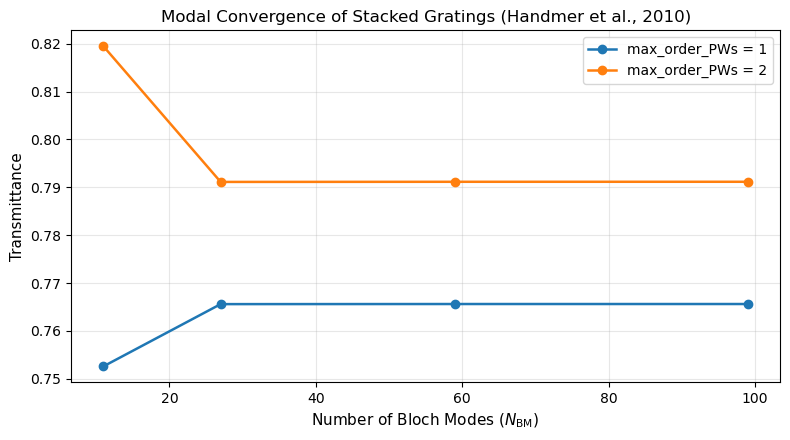

In [3]:
fig, ax = plt.subplots(figsize=(8, 4.5), dpi=100)
for pws, t_vals in results.items():
    ax.plot(bm_counts, t_vals, '-o', lw=1.8, label=f'max_order_PWs = {pws}')

ax.set_xlabel('Number of Bloch Modes ($N_{\mathrm{BM}}$)', fontsize=11)
ax.set_ylabel('Transmittance', fontsize=11)
ax.set_title('Modal Convergence of Stacked Gratings (Handmer et al., 2010)', fontsize=12)
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()


## Physical Interpretation
- Convergence occurs monotonically as higher-order evanescent Bloch modes capture the localized near-field boundary coupling.
- Beyond $N_{\mathrm{BM}} \approx 60$, transmittance stabilizes to four significant figures.
